In [75]:
!pip install -q rocketpy

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from rocketpy import Environment, SolidMotor, Rocket, Flight

# ==============================================================================
# DADOS OFICIAIS DO MOTOR (Jorge2grãos)
# ==============================================================================
RAIO_NOZZLE_OFICIAL = 0.0073   # m
RAIO_GARGANTA_ORIG  = 0.0029   # m
RAIO_MODIFICADO     = 0.0073   # Garganta igual ao nozzle [m]

N_GRAOS     = 2
ESPACAMENTO = 0.0              # m
DENSIDADE   = 1841.0           # kg/m³
R_EXTERNO   = 0.0195           # m
R_INTERNO   = 0.0068           # m
ALTURA_GRAO = 0.076            # m

# ==============================================================================
# 1. CURVA ORIGINAL DO MOTOR (.ENG)
# ==============================================================================
conteudo_eng_original = """I283 46.0 280.0 0 0.294 1.104 METEOR
    0.0001 0.0001
    0.0097 166.5
    0.0145 212.5201
    0.0189 235.5249
    0.0231 247.9984
    0.0273 253.5852
    0.0314 254.4532
    0.0356 255.1943
    0.0398 255.8995
    0.0439 256.5922
    0.0481 257.2788
    0.0523 257.9607
    0.0564 258.6385
    0.0606 259.3123
    0.0648 259.9822
    0.0689 260.6481
    0.0731 261.3101
    0.0773 261.9681
    0.0814 262.6221
    0.0856 263.2722
    0.0897 263.9184
    0.0939 264.5605
    0.0981 265.1987
    0.1022 265.8329
    0.1064 266.4632
    0.1105 267.0895
    0.1147 267.7118
    0.1188 268.3301
    0.123 268.9444
    0.1272 269.5548
    0.1313 270.1612
    0.1355 270.7635
    0.1396 271.3619
    0.1438 271.9563
    0.1479 272.5467
    0.1521 273.1331
    0.1562 273.7155
    0.1604 274.2939
    0.1645 274.8682
    0.1687 275.4386
    0.1728 276.005
    0.177 276.5673
    0.1811 277.1256
    0.1853 277.68
    0.1894 278.2303
    0.1936 278.7765
    0.1977 279.3188
    0.2019 279.857
    0.206 280.3912
    0.2101 280.9214
    0.2143 281.4475
    0.2184 281.9696
    0.2226 282.4877
    0.2267 283.0041
    0.2309 283.5213
    0.235 284.0343
    0.2392 284.5432
    0.2433 285.0479
    0.2474 285.5485
    0.2516 286.045
    0.2557 286.5373
    0.2599 287.0254
    0.264 287.5094
    0.2681 287.9892
    0.2723 288.4648
    0.2764 288.9364
    0.2805 289.4037
    0.2847 289.8669
    0.2888 290.326
    0.293 290.7808
    0.2971 291.2316
    0.3012 291.6782
    0.3054 292.1206
    0.3095 292.5588
    0.3136 292.9929
    0.3178 293.4229
    0.3219 293.8487
    0.326 294.2703
    0.3302 294.6878
    0.3343 295.1011
    0.3384 295.5102
    0.3426 295.9152
    0.3467 296.3161
    0.3508 296.7127
    0.355 297.1053
    0.3591 297.4936
    0.3632 297.8778
    0.3674 298.2578
    0.3715 298.6337
    0.3756 299.0054
    0.3797 299.373
    0.3839 299.7363
    0.388 300.0956
    0.3921 300.4506
    0.3963 300.8015
    0.4004 301.1483
    0.4045 301.4908
    0.4086 301.8292
    0.4128 302.1635
    0.4169 302.4936
    0.421 302.8195
    0.4252 303.1412
    0.4293 303.4588
    0.4334 303.7723
    0.4375 304.0815
    0.4417 304.3866
    0.4458 304.6876
    0.4499 304.9843
    0.454 305.2769
    0.4582 305.5654
    0.4623 305.8496
    0.4664 306.1297
    0.4705 306.4057
    0.4747 306.6775
    0.4788 306.9451
    0.4829 307.2085
    0.487 307.4678
    0.4911 307.7229
    0.4953 307.9739
    0.4994 308.2206
    0.5035 308.4633
    0.5076 308.7017
    0.5118 308.936
    0.5159 309.1661
    0.52 309.392
    0.5241 309.6138
    0.5282 309.8314
    0.5324 310.0449
    0.5365 310.2542
    0.5406 310.4593
    0.5447 310.6602
    0.5488 310.857
    0.553 311.0496
    0.5571 311.238
    0.5612 311.4223
    0.5653 311.6024
    0.5694 311.7783
    0.5736 311.9501
    0.5777 312.1177
    0.5818 312.2811
    0.5859 312.4404
    0.59 312.5955
    0.5942 312.7464
    0.5983 312.8931
    0.6024 313.0357
    0.6065 313.1741
    0.6106 313.3084
    0.6148 313.4385
    0.6189 313.5644
    0.623 313.6861
    0.6271 313.8037
    0.6312 313.9171
    0.6353 314.0263
    0.6395 314.1314
    0.6436 314.2323
    0.6477 314.329
    0.6518 314.4216
    0.6559 314.5099
    0.6601 314.5942
    0.6642 314.6742
    0.6683 314.7501
    0.6724 314.8218
    0.6765 314.8893
    0.6806 314.9527
    0.6848 315.0119
    0.6889 315.0669
    0.693 315.1177
    0.6971 315.1644
    0.7012 315.2069
    0.7053 315.2453
    0.7095 315.2795
    0.7136 315.3095
    0.7177 315.3353
    0.7218 315.357
    0.7259 315.3745
    0.73 315.3878
    0.7342 315.3969
    0.7383 315.4019
    0.7424 315.4027
    0.7465 315.3994
    0.7506 315.3918
    0.7547 315.3801
    0.7589 315.3643
    0.763 315.3442
    0.7671 315.32
    0.7712 315.2916
    0.7753 315.2591
    0.7794 315.2224
    0.7836 315.1815
    0.7877 315.1364
    0.7918 315.0872
    0.7959 315.0338
    0.8 314.9762
    0.8042 314.9144
    0.8083 314.8485
    0.8124 314.7784
    0.8165 314.7042
    0.8206 314.6257
    0.8247 314.5431
    0.8289 314.4564
    0.833 314.3654
    0.8371 314.2703
    0.8412 314.171
    0.8453 314.0676
    0.8494 313.96
    0.8536 313.8482
    0.8577 313.7322
    0.8618 313.6121
    0.8659 313.4878
    0.87 313.3593
    0.8742 313.2266
    0.8783 313.0898
    0.8824 312.9488
    0.8865 312.8037
    0.8906 312.6543
    0.8947 312.5009
    0.8989 312.3432
    0.903 312.1813
    0.9071 312.0153
    0.9112 311.8452
    0.9153 311.6708
    0.9195 311.4923
    0.9236 311.3096
    0.9277 311.1227
    0.9318 310.9317
    0.9359 310.7365
    0.9401 310.5371
    0.9442 310.3336
    0.9483 310.1259
    0.9524 309.914
    0.9566 309.698
    0.9607 309.4777
    0.9648 309.2534
    0.9689 309.0248
    0.973 308.7921
    0.9772 308.5552
    0.9813 308.3141
    0.9854 308.0689
    0.9895 307.8195
    0.9936 307.5659
    0.9978 307.3081
    1.0019 307.0462
    1.006 306.7802
    1.0101 306.5099
    1.0143 306.2355
    1.0184 305.9569
    1.0225 305.6742
    1.0266 305.3872
    1.0308 305.0961
    1.0349 304.8009
    1.039 304.5014
    1.0431 304.1979
    1.0473 303.8901
    1.0514 303.5782
    1.0555 303.2621
    1.0596 302.9418
    1.0638 302.6174
    1.0679 302.2888
    1.072 301.956
    1.0762 301.619
    1.0803 301.2779
    1.0844 300.9327
    1.0885 300.5832
    1.0927 300.2296
    1.0968 299.8719
    1.1009 299.5099
    1.1051 299.1438
    1.1092 298.7736
    1.1133 298.3991
    1.1174 298.0205
    1.1216 297.6378
    1.1257 297.2508
    1.1298 296.8597
    1.134 296.4645
    1.1381 296.0651
    1.1422 295.6615
    1.1464 295.2537
    1.1505 294.8418
    1.1546 294.4257
    1.1594 227.7954
    1.1642 176.0558
    1.169 135.8268
    1.1738 104.5796
    1.1786 80.3357
    1.1834 61.5484
    1.1882 47.0087
    1.193 35.7725
    1.1978 27.1027
    1.2026 20.4243
    1.2074 15.2888
    1.2122 11.3469
    1.217 8.3259
    1.2218 6.013
    1.2266 4.2412
    1.2314 0.0001"""

caminho_eng_original   = "/content/Jorge2graos_original.eng"
caminho_eng_modificado = "/content/Jorge2graos_throat_igual_nozzle.eng"

with open(caminho_eng_original, "w") as f:
    f.write(conteudo_eng_original)

# ==============================================================================
# 2. BALÍSTICA INTERNA DO KNSB COM A GEOMETRIA OFICIAL DOS GRÃOS
# ==============================================================================
gamma = 1.13
R_gas = 208.0
T0 = 1600.0
Pa = 101325.0
c_star = np.sqrt(R_gas * T0 / gamma) * ((gamma + 1) / 2) ** ((gamma + 1) / (2 * (gamma - 1)))
cstar_eff = c_star * 0.92

def taxa_queima_knsb(P_pa):
    P_mpa = max(P_pa - Pa, 0.0) / 1e6
    if P_mpa <= 0:
        return 0.0
    if P_mpa < 0.807:
        r_mm = 8.875 * (P_mpa ** 0.619)
    elif P_mpa < 1.503:
        r_mm = 7.553 * (P_mpa ** 0.009)
    elif P_mpa < 3.792:
        r_mm = 3.841 * (P_mpa ** 0.688)
    else:
        r_mm = 17.20 * (P_mpa ** -0.148)
    return r_mm / 1000.0

def simular_garganta_igual_nozzle(r_t, r_e):
    A_t = np.pi * r_t**2
    crit_ratio = ((gamma + 1) / 2) ** (gamma / (gamma - 1))
    dt = 0.1
    t, r_int, L = 0.0, R_INTERNO, ALTURA_GRAO
    ts, Fs, Pcs = [0.0], [0.0], [Pa]

    while r_int < R_EXTERNO and L > 0 and t < 40.0:
        A_b = N_GRAOS * (2 * np.pi * r_int * L + 2 * np.pi * (R_EXTERNO**2 - r_int**2))

        def balanco_massa(Pc):
            m_gerada = DENSIDADE * A_b * taxa_queima_knsb(Pc)
            if Pc / Pa >= crit_ratio:
                m_bocal = Pc * A_t / cstar_eff
            else:
                M_t = np.sqrt((2 / (gamma - 1)) * ((Pc / Pa) ** ((gamma - 1) / gamma) - 1))
                m_bocal = (Pc * A_t / cstar_eff) * M_t * (((gamma + 1) / 2) / (1 + ((gamma - 1) / 2) * M_t**2)) ** ((gamma + 1) / (2 * (gamma - 1)))
            return m_gerada - m_bocal

        if balanco_massa(Pa + 50.0) < 0:
            Pc = Pa + 35.0
        else:
            Pc = brentq(balanco_massa, Pa + 50.0, 20e6)

        rb = max(taxa_queima_knsb(Pc), 0.0004)
        M_t = np.sqrt((2 / (gamma - 1)) * ((Pc / Pa) ** ((gamma - 1) / gamma) - 1))
        T_e = T0 / (1 + ((gamma - 1) / 2) * M_t**2)
        v_e = M_t * np.sqrt(gamma * R_gas * T_e)
        m_bocal = (Pc * A_t / cstar_eff) * M_t * (((gamma + 1) / 2) / (1 + ((gamma - 1) / 2) * M_t**2)) ** ((gamma + 1) / (2 * (gamma - 1)))
        F = 0.95 * m_bocal * v_e

        t += dt
        r_int += rb * dt
        L -= 2 * rb * dt
        ts.append(t)
        Fs.append(F)
        Pcs.append(Pc)

    ts.append(t + 0.05)
    Fs.append(0.0)
    Pcs.append(Pa)
    return np.array(ts), np.array(Fs), np.array(Pcs)

tempos_mod, empuxo_mod, pressao_mod = simular_garganta_igual_nozzle(r_t=RAIO_MODIFICADO, r_e=RAIO_MODIFICADO)
novo_burn_time = float(tempos_mod[-1])

linhas_orig = conteudo_eng_original.splitlines()
tempos_orig, empuxo_orig = [], []
for linha in linhas_orig[1:]:
    t, emp = map(float, linha.split())
    tempos_orig.append(t)
    empuxo_orig.append(emp)

with open(caminho_eng_modificado, "w") as f:
    f.write("A1 46.0 280.0 0 0.294 1.104 METEOR\n")
    for t, emp in zip(tempos_mod, empuxo_mod):
        f.write(f"    {t:.4f} {max(emp, 0.0001):.4f}\n")

print(f"✅ Curvas geradas com os grãos oficiais! Raio throat = nozzle: {RAIO_MODIFICADO} m")
print(f"   Tempo de queima modificado: {novo_burn_time:.2f} s | Empuxo máx.: {empuxo_mod.max():.4f} N")

✅ Curvas geradas com os grãos oficiais! Raio throat = nozzle: 0.0073 m
   Tempo de queima modificado: 31.85 s | Empuxo máx.: 0.0121 N


Impulso Total Original:   347.956 Ns | Empuxo Médio: 282.57 N | Burn time: 1.23 s
Impulso Total Modificado: 0.384 Ns | Empuxo Médio: 0.0121 N | Burn time: 31.85 s


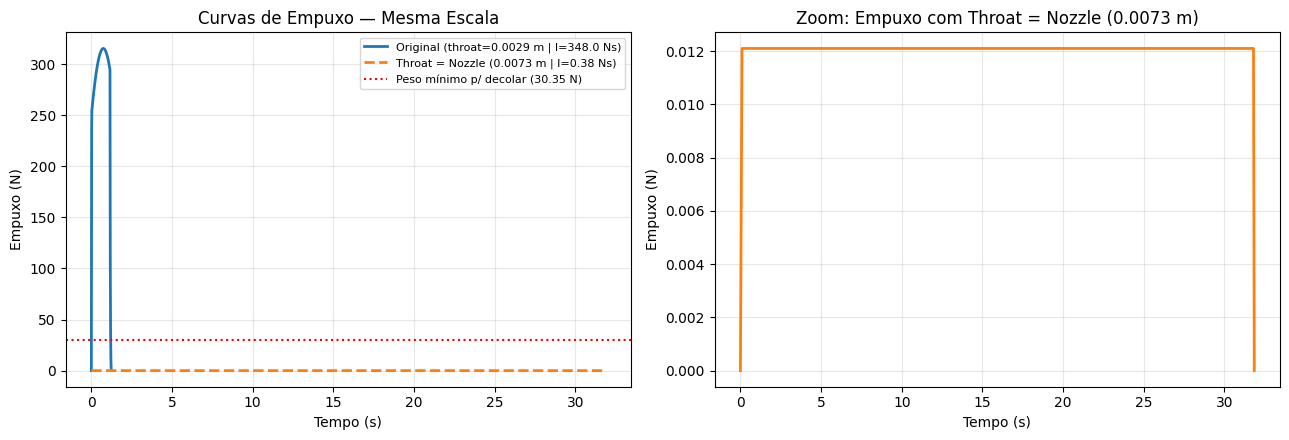

In [76]:
Jorge2grãos = SolidMotor(
    thrust_source=caminho_eng_original,
    dry_mass=0.810,
    dry_inertia=(0.02629, 0.02629, 0.000429),
    nozzle_radius=RAIO_NOZZLE_OFICIAL,
    throat_radius=RAIO_GARGANTA_ORIG,
    grain_number=N_GRAOS,
    grain_density=DENSIDADE,
    grain_outer_radius=R_EXTERNO,
    grain_initial_inner_radius=R_INTERNO,
    grain_initial_height=ALTURA_GRAO,
    grain_separation=ESPACAMENTO,
    grains_center_of_mass_position=0.155,
    center_of_dry_mass_position=0.199,
    nozzle_position=0,
    burn_time=1.2314,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

Motor_Modificado = SolidMotor(
    thrust_source=caminho_eng_modificado,
    dry_mass=0.810,
    dry_inertia=(0.02629, 0.02629, 0.000429),
    nozzle_radius=RAIO_MODIFICADO,
    throat_radius=RAIO_MODIFICADO,
    grain_number=N_GRAOS,
    grain_density=DENSIDADE,
    grain_outer_radius=R_EXTERNO,
    grain_initial_inner_radius=R_INTERNO,
    grain_initial_height=ALTURA_GRAO,
    grain_separation=ESPACAMENTO,
    grains_center_of_mass_position=0.155,
    center_of_dry_mass_position=0.199,
    nozzle_position=0,
    burn_time=novo_burn_time,
    interpolation_method="linear",  # Evita o nan da spline cúbica em curvas planas
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

# Garante valor numérico válido mesmo se o integrador interno falhar
imp_mod = Motor_Modificado.total_impulse
if np.isnan(imp_mod):
    imp_mod = float(np.trapezoid(empuxo_mod, tempos_mod))
emp_medio_mod = imp_mod / Motor_Modificado.burn_out_time

print(f"Impulso Total Original:   {Jorge2grãos.total_impulse:.3f} Ns | Empuxo Médio: {Jorge2grãos.average_thrust:.2f} N | Burn time: {Jorge2grãos.burn_out_time:.2f} s")
print(f"Impulso Total Modificado: {imp_mod:.3f} Ns | Empuxo Médio: {emp_medio_mod:.4f} N | Burn time: {Motor_Modificado.burn_out_time:.2f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(tempos_orig, empuxo_orig, label=f"Original (throat=0.0029 m | I={Jorge2grãos.total_impulse:.1f} Ns)", lw=2)
ax1.plot(tempos_mod, empuxo_mod, "--", label=f"Throat = Nozzle ({RAIO_MODIFICADO} m | I={imp_mod:.2f} Ns)", lw=2)
ax1.axhline(30.35, color="red", linestyle=":", label="Peso mínimo p/ decolar (30.35 N)")
ax1.set_title("Curvas de Empuxo — Mesma Escala")
ax1.set_xlabel("Tempo (s)")
ax1.set_ylabel("Empuxo (N)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8)

ax2.plot(tempos_mod, empuxo_mod, color="tab:orange", lw=2)
ax2.set_title(f"Zoom: Empuxo com Throat = Nozzle ({RAIO_MODIFICADO} m)")
ax2.set_xlabel("Tempo (s)")
ax2.set_ylabel("Empuxo (N)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

--- COMPARAÇÃO DE VOO (DADOS OFICIAIS) ---
Tempo de queima:      1.23 s (Orig) vs 31.85 s (Mod)
Vel. saída do trilho: 14.71 m/s (Orig) vs 0.00 m/s (Mod)
Apogeu AGL:           559.14 m (Orig) vs 0.00 m (Mod)


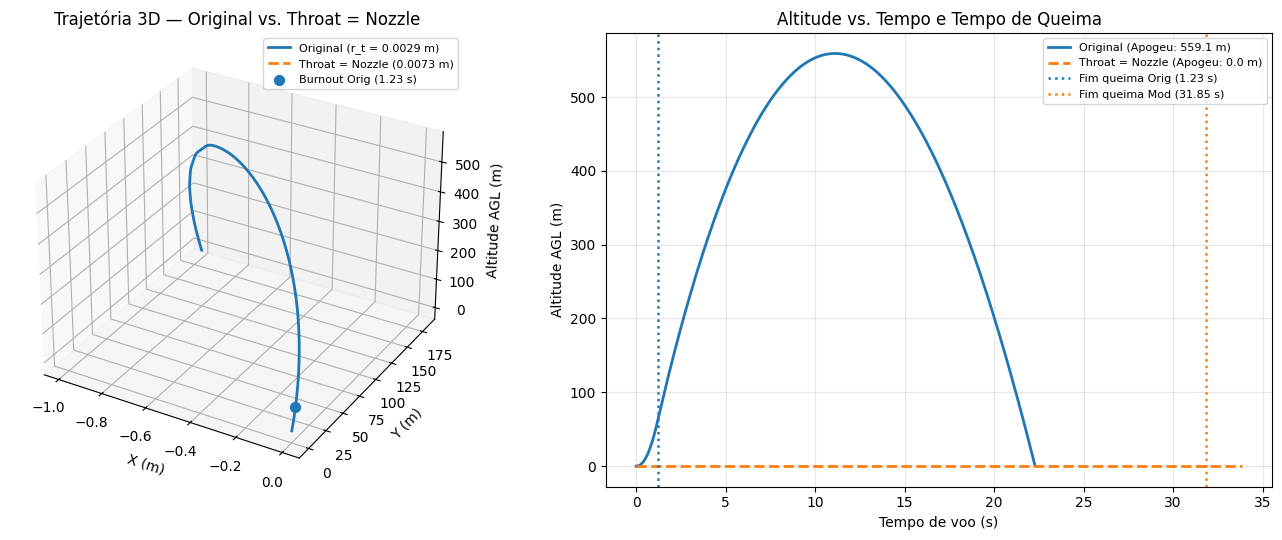

In [77]:
env = Environment(latitude=-19.619, longitude=-43.226, elevation=800)

def criar_foguete_falcons(motor_escolhido):
    foguete = Rocket(
        radius=0.032,
        mass=1.990,
        inertia=(0.305, 0.305, 0.002),
        power_off_drag=0.38,
        power_on_drag=0.38,
        center_of_mass_without_motor=0.623,
        coordinate_system_orientation="nose_to_tail",
    )
    foguete.add_motor(motor_escolhido, position=1.130)
    foguete.add_nose(length=0.178, kind="ogive", position=0.0)
    foguete.add_trapezoidal_fins(n=4, root_chord=0.11, tip_chord=0.05, span=0.065, position=0.965)
    foguete.add_tail(top_radius=0.032, bottom_radius=0.025, length=0.04, position=1.070)
    foguete.set_rail_buttons(upper_button_position=0.50, lower_button_position=0.95)
    return foguete

Foguete_Orig = criar_foguete_falcons(Jorge2grãos)
Foguete_Mod  = criar_foguete_falcons(Motor_Modificado)

Voo_Orig = Flight(rocket=Foguete_Orig, environment=env, rail_length=2.0, inclination=85, heading=0)
Voo_Mod  = Flight(rocket=Foguete_Mod,  environment=env, rail_length=2.0, inclination=85, heading=0)

apogeu_orig = Voo_Orig.apogee - env.elevation
apogeu_mod  = max(0.0, Voo_Mod.apogee - env.elevation)

print("--- COMPARAÇÃO DE VOO (DADOS OFICIAIS) ---")
print(f"Tempo de queima:      {Jorge2grãos.burn_out_time:.2f} s (Orig) vs {Motor_Modificado.burn_out_time:.2f} s (Mod)")
print(f"Vel. saída do trilho: {Voo_Orig.out_of_rail_velocity:.2f} m/s (Orig) vs {Voo_Mod.out_of_rail_velocity:.2f} m/s (Mod)")
print(f"Apogeu AGL:           {apogeu_orig:.2f} m (Orig) vs {apogeu_mod:.2f} m (Mod)")

t1 = np.linspace(0, Voo_Orig.t_final, 500)
t2_fim = min(Voo_Mod.t_final, novo_burn_time + 2.0)
t2 = np.linspace(0, t2_fim, 500)

fig = plt.figure(figsize=(14, 5.5))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(Voo_Orig.x(t1), Voo_Orig.y(t1), Voo_Orig.z(t1) - env.elevation, label="Original (r_t = 0.0029 m)", lw=2)
ax1.plot(Voo_Mod.x(t2),  Voo_Mod.y(t2),  np.maximum(0, Voo_Mod.z(t2) - env.elevation), "--", label=f"Throat = Nozzle ({RAIO_MODIFICADO} m)", lw=2)
ax1.scatter(Voo_Orig.x(Jorge2grãos.burn_out_time), Voo_Orig.y(Jorge2grãos.burn_out_time),
            Voo_Orig.z(Jorge2grãos.burn_out_time) - env.elevation, color="tab:blue", s=50, label=f"Burnout Orig ({Jorge2grãos.burn_out_time:.2f} s)")
ax1.set_title("Trajetória 3D — Original vs. Throat = Nozzle")
ax1.set_xlabel("X (m)")
ax1.set_ylabel("Y (m)")
ax1.set_zlabel("Altitude AGL (m)")
ax1.legend(loc="best", fontsize=8)

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t1, Voo_Orig.z(t1) - env.elevation, label=f"Original (Apogeu: {apogeu_orig:.1f} m)", lw=2)
ax2.plot(t2, np.maximum(0, Voo_Mod.z(t2) - env.elevation), "--", label=f"Throat = Nozzle (Apogeu: {apogeu_mod:.1f} m)", lw=2)
ax2.axvline(Jorge2grãos.burn_out_time, color="tab:blue", linestyle=":", lw=1.8, label=f"Fim queima Orig ({Jorge2grãos.burn_out_time:.2f} s)")
ax2.axvline(Motor_Modificado.burn_out_time, color="tab:orange", linestyle=":", lw=1.8, label=f"Fim queima Mod ({Motor_Modificado.burn_out_time:.2f} s)")
ax2.set_title("Altitude vs. Tempo e Tempo de Queima")
ax2.set_xlabel("Tempo de voo (s)")
ax2.set_ylabel("Altitude AGL (m)")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best", fontsize=8)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/rocketpy/motors/motor.py:998: UserWarning: burn_time argument (0, 1.2000000000000004) is out of thrust source time range. Using thrust_source boundary times instead: (0, 1.2) s.
If you want to change the burn out time of the curve please use the 'reshape_thrust_curve' argument.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rocketpy/motors/motor.py:998: UserWarning: burn_time argument (0, 1.1500000000000004) is out of thrust source time range. Using thrust_source boundary times instead: (0, 1.15) s.
If you want to change the burn out time of the curve please use the 'reshape_thrust_curve' argument.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rocketpy/motors/motor.py:998: UserWarning: burn_time argument (0, 1.1000000000000003) is out of thrust source time range. Using thrust_source boundary times instead: (0, 1.1) s.
If you want to change the burn out time of the curve please use the 'reshape_thrust_curve' argument.
  warnin

🎯 GARGANTA MAIS EFICIENTE (com Pc <= 100 bar):
   Raio ótimo da garganta: 3.01 mm (Original Falcons: 2.90 mm)
   Pressão máx. de câmara: 87.9 bar
   Impulso Total:          393.4 Ns
   Tempo de queima:        1.10 s
   Apogeu estimado:        631.3 m AGL


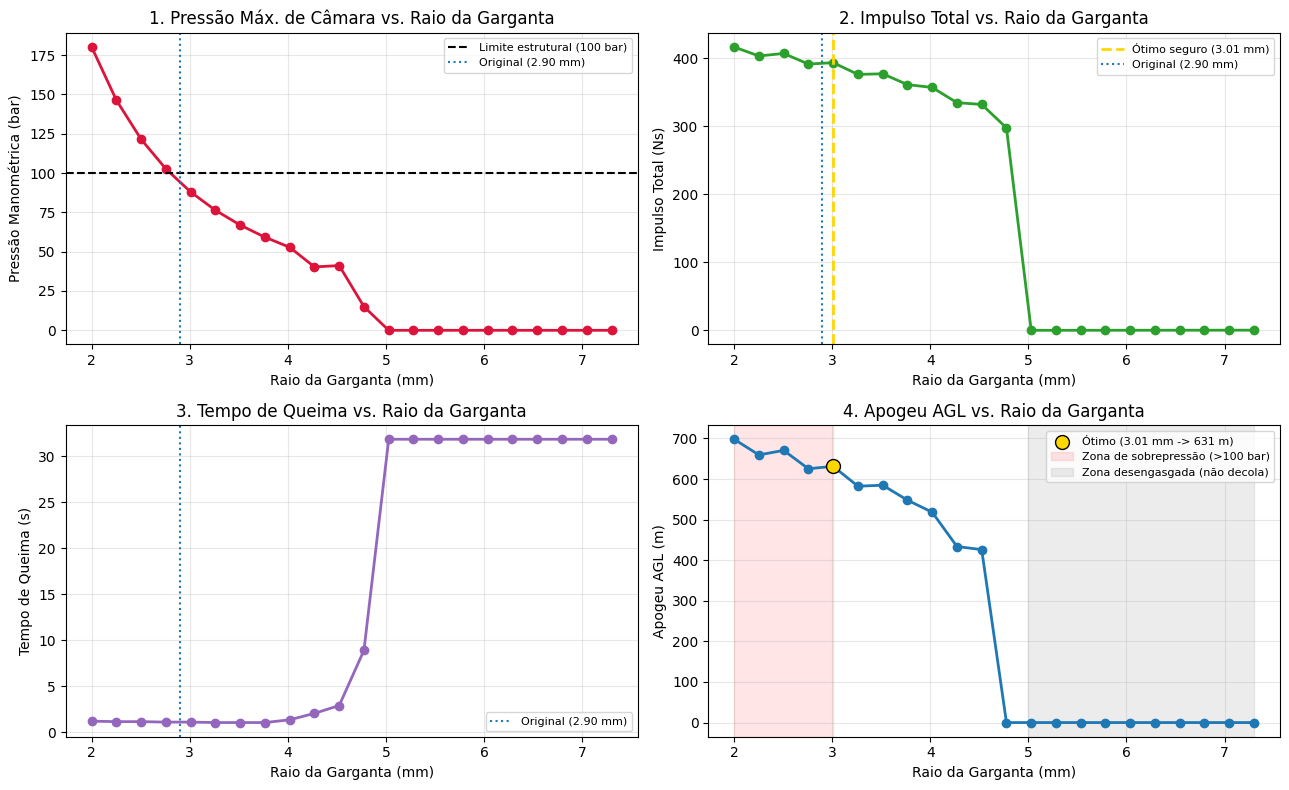

In [78]:
# ==============================================================================
# CÉLULA 4 — VARREDURA PARAMÉTRICA: TAMANHO ÓTIMO E LIMITES FÍSICOS DA GARGANTA
# ==============================================================================
from scipy.optimize import brentq

# Limites físicos:
# - Inferior: 2.0 mm (abaixo disso Pc ultrapassa 170 bar -> risco estrutural / CATO)
# - Superior: 7.3 mm (limite geométrico: r_t = r_e = 0.0073 m, sem seção divergente)
raios_teste = np.linspace(0.0020, RAIO_NOZZLE_OFICIAL, 22)

def simular_garganta_completa(r_t, r_e=RAIO_NOZZLE_OFICIAL):
    A_t = np.pi * r_t**2
    A_e = np.pi * r_e**2
    eps = A_e / A_t
    crit_ratio = ((gamma + 1) / 2) ** (gamma / (gamma - 1))

    if eps > 1.0001:
        f_area = lambda M: (1 / M) * (((2 / (gamma + 1)) * (1 + ((gamma - 1) / 2) * M**2)) ** ((gamma + 1) / (2 * (gamma - 1)))) - eps
        M_e = brentq(f_area, 1.001, 15.0)
        Pe_Pc = (1 + ((gamma - 1) / 2) * M_e**2) ** (-gamma / (gamma - 1))
    else:
        M_e = 1.0
        Pe_Pc = (2 / (gamma + 1)) ** (gamma / (gamma - 1))

    dt = 0.05
    t, r_int, L = 0.0, R_INTERNO, ALTURA_GRAO
    ts, Fs, Pcs = [0.0], [0.0], [Pa]

    while r_int < R_EXTERNO and L > 0 and t < 40.0:
        A_b = N_GRAOS * (2 * np.pi * r_int * L + 2 * np.pi * (R_EXTERNO**2 - r_int**2))

        def bal(Pc):
            m_ger = DENSIDADE * A_b * taxa_queima_knsb(Pc)
            if Pc / Pa >= crit_ratio:
                m_noz = Pc * A_t / cstar_eff
            else:
                M_t = np.sqrt((2 / (gamma - 1)) * ((Pc / Pa) ** ((gamma - 1) / gamma) - 1))
                m_noz = (Pc * A_t / cstar_eff) * M_t * (((gamma + 1) / 2) / (1 + ((gamma - 1) / 2) * M_t**2)) ** ((gamma + 1) / (2 * (gamma - 1)))
            return m_ger - m_noz

        if bal(Pa + 50.0) < 0:
            Pc = Pa + 35.0
        else:
            Pc = brentq(bal, Pa + 50.0, 50e6)

        rb = max(taxa_queima_knsb(Pc), 0.0004)
        if Pc / Pa >= crit_ratio:
            Pe = Pe_Pc * Pc
            CF = np.sqrt((2 * gamma**2 / (gamma - 1)) * ((2 / (gamma + 1)) ** ((gamma + 1) / (gamma - 1))) * (1 - (Pe / Pc) ** ((gamma - 1) / gamma))) + (Pe / Pc - Pa / Pc) * eps
            F = 0.95 * CF * Pc * A_t
        else:
            M_t = np.sqrt((2 / (gamma - 1)) * ((Pc / Pa) ** ((gamma - 1) / gamma) - 1))
            T_e = T0 / (1 + ((gamma - 1) / 2) * M_t**2)
            v_e = M_t * np.sqrt(gamma * R_gas * T_e)
            m_noz = (Pc * A_t / cstar_eff) * M_t * (((gamma + 1) / 2) / (1 + ((gamma - 1) / 2) * M_t**2)) ** ((gamma + 1) / (2 * (gamma - 1)))
            F = 0.95 * m_noz * v_e

        t += dt
        r_int += rb * dt
        L -= 2 * rb * dt
        ts.append(t)
        Fs.append(F)
        Pcs.append(Pc)

    ts.append(t + 0.05)
    Fs.append(0.0)
    Pcs.append(Pa)
    return np.array(ts), np.array(Fs), np.array(Pcs)

# Listas para armazenar os resultados
lista_r_mm, lista_pc_bar, lista_imp, lista_tburn, lista_apogeu = [], [], [], [], []

for r in raios_teste:
    ts_i, Fs_i, Pcs_i = simular_garganta_completa(r)
    imp_i = float(np.trapezoid(Fs_i, ts_i)) if hasattr(np, "trapezoid") else float(np.trapz(Fs_i, ts_i))
    pc_max_bar = (Pcs_i.max() - Pa) / 1e5
    t_burn_i = float(ts_i[-1])

    # Salva .eng temporário e roda o voo no RocketPy
    arq_temp = "/content/temp_sweep.eng"
    with open(arq_temp, "w") as f:
        f.write("SWEEP 46.0 280.0 0 0.294 1.104 METEOR\n")
        for ti, fi in zip(ts_i, Fs_i):
            f.write(f"    {ti:.4f} {max(fi, 0.0001):.4f}\n")

    motor_i = SolidMotor(
        thrust_source=arq_temp,
        dry_mass=0.810,
        dry_inertia=(0.02629, 0.02629, 0.000429),
        nozzle_radius=RAIO_NOZZLE_OFICIAL,
        throat_radius=r,
        grain_number=N_GRAOS,
        grain_density=DENSIDADE,
        grain_outer_radius=R_EXTERNO,
        grain_initial_inner_radius=R_INTERNO,
        grain_initial_height=ALTURA_GRAO,
        grain_separation=ESPACAMENTO,
        grains_center_of_mass_position=0.155,
        center_of_dry_mass_position=0.199,
        nozzle_position=0,
        burn_time=t_burn_i,
        interpolation_method="linear",
        coordinate_system_orientation="nozzle_to_combustion_chamber",
    )

    foguete_i = criar_foguete_falcons(motor_i)
    voo_i = Flight(rocket=foguete_i, environment=env, rail_length=2.0, inclination=85, heading=0)
    apogeu_i = max(0.0, voo_i.apogee - env.elevation)

    lista_r_mm.append(r * 1000)
    lista_pc_bar.append(pc_max_bar)
    lista_imp.append(imp_i)
    lista_tburn.append(t_burn_i)
    lista_apogeu.append(apogeu_i)

# Encontra o ponto mais eficiente dentro do limite estrutural seguro (Pc <= 100 bar)
limite_seguro_bar = 100.0
indices_seguros = [i for i, p in enumerate(lista_pc_bar) if p <= limite_seguro_bar]
idx_otimo = max(indices_seguros, key=lambda i: lista_apogeu[i])

print("=================================================================")
print(f"🎯 GARGANTA MAIS EFICIENTE (com Pc <= {limite_seguro_bar:.0f} bar):")
print(f"   Raio ótimo da garganta: {lista_r_mm[idx_otimo]:.2f} mm (Original Falcons: 2.90 mm)")
print(f"   Pressão máx. de câmara: {lista_pc_bar[idx_otimo]:.1f} bar")
print(f"   Impulso Total:          {lista_imp[idx_otimo]:.1f} Ns")
print(f"   Tempo de queima:        {lista_tburn[idx_otimo]:.2f} s")
print(f"   Apogeu estimado:        {lista_apogeu[idx_otimo]:.1f} m AGL")
print("=================================================================")

# ==============================================================================
# PAINEL DE 4 GRÁFICOS DO COMPORTAMENTO FÍSICO
# ==============================================================================
fig, axs = plt.subplots(2, 2, figsize=(13, 8))

# 1. Pressão de Câmara vs Raio da Garganta
axs[0, 0].plot(lista_r_mm, lista_pc_bar, "o-", color="crimson", lw=2)
axs[0, 0].axhline(limite_seguro_bar, color="black", linestyle="--", label=f"Limite estrutural ({limite_seguro_bar:.0f} bar)")
axs[0, 0].axvline(2.90, color="tab:blue", linestyle=":", label="Original (2.90 mm)")
axs[0, 0].set_title("1. Pressão Máx. de Câmara vs. Raio da Garganta")
axs[0, 0].set_xlabel("Raio da Garganta (mm)")
axs[0, 0].set_ylabel("Pressão Manométrica (bar)")
axs[0, 0].grid(True, alpha=0.3)
axs[0, 0].legend(fontsize=8)

# 2. Impulso Total vs Raio da Garganta
axs[0, 1].plot(lista_r_mm, lista_imp, "o-", color="tab:green", lw=2)
axs[0, 1].axvline(lista_r_mm[idx_otimo], color="gold", linestyle="--", lw=2, label=f"Ótimo seguro ({lista_r_mm[idx_otimo]:.2f} mm)")
axs[0, 1].axvline(2.90, color="tab:blue", linestyle=":", label="Original (2.90 mm)")
axs[0, 1].set_title("2. Impulso Total vs. Raio da Garganta")
axs[0, 1].set_xlabel("Raio da Garganta (mm)")
axs[0, 1].set_ylabel("Impulso Total (Ns)")
axs[0, 1].grid(True, alpha=0.3)
axs[0, 1].legend(fontsize=8)

# 3. Tempo de Queima vs Raio da Garganta
axs[1, 0].plot(lista_r_mm, lista_tburn, "o-", color="tab:purple", lw=2)
axs[1, 0].axvline(2.90, color="tab:blue", linestyle=":", label="Original (2.90 mm)")
axs[1, 0].set_title("3. Tempo de Queima vs. Raio da Garganta")
axs[1, 0].set_xlabel("Raio da Garganta (mm)")
axs[1, 0].set_ylabel("Tempo de Queima (s)")
axs[1, 0].grid(True, alpha=0.3)
axs[1, 0].legend(fontsize=8)

# 4. Apogeu AGL vs Raio da Garganta
axs[1, 1].plot(lista_r_mm, lista_apogeu, "o-", color="tab:blue", lw=2)
axs[1, 1].scatter([lista_r_mm[idx_otimo]], [lista_apogeu[idx_otimo]], color="gold", edgecolor="black", s=100, zorder=5, label=f"Ótimo ({lista_r_mm[idx_otimo]:.2f} mm -> {lista_apogeu[idx_otimo]:.0f} m)")
axs[1, 1].axvspan(2.0, lista_r_mm[idx_otimo], color="red", alpha=0.1, label="Zona de sobrepressão (>100 bar)")
axs[1, 1].axvspan(5.0, 7.3, color="gray", alpha=0.15, label="Zona desengasgada (não decola)")
axs[1, 1].set_title("4. Apogeu AGL vs. Raio da Garganta")
axs[1, 1].set_xlabel("Raio da Garganta (mm)")
axs[1, 1].set_ylabel("Apogeu AGL (m)")
axs[1, 1].grid(True, alpha=0.3)
axs[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()